# 114 · 3 attention: where the lasers and the freq bands look
Every attention map of `s9-transformer-vase-1k` (ep1000) on its eval split (up to 40 samples per eval split, ~2.2k). The model never returns its
weights (`Block` calls `F.scaled_dot_product_attention`), so a forward hook on each `Block` grabs its input and the notebook recomputes
`softmax(q kᵀ / √d_h)` from that block's own `n1` + `qkv`; a check rebuilds each block's output from those weights.

The encoder is two transformers in a row, not one over laser×freq tokens:
1. **freq blocks** (2 layers, 4 heads): per laser, self-attention over its 19 freq bands (64 bins, ~49 Hz each). Batch = (sample, laser).
2. **band pooling**: one learned query per head (`pool_q`) attends over the 19 bands of each laser → gates the bands → `pool_o` → 1 token per laser.
3. **laser blocks** (2 layers, 4 heads): self-attention over the 100 laser tokens (10×10 wall grid, laser `l` = row `l // 10`, col `l % 10`).
4. **readout**: `LayerNorm → Flatten → Linear(100·128 → 1024)`; every laser slot has its own weights. No token is pooled.

In [1]:
import os, sys, json, math
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); import dataset as D9
from arch.transformer import Transformer

RUN, N_PER_EVAL, SEED, DEV = "s9-transformer-vase-1k", 40, 0, "cuda"
assert json.loads((ROOT / f"runs/{RUN}/args.json").read_text())["window"] == "tukey"

# the split src9 trains on; up to N_PER_EVAL samples per eval split
samples, idx = D9.load_splits()
metas, dirs = list(samples.values()), list(samples)
rng = np.random.default_rng(SEED)
EV = sorted({int(i) for n, ids in idx.items() if n != "train" for i in rng.choice(ids, min(N_PER_EVAL, len(ids)), replace=False)})
boxes = sorted({m["box"] for m in metas})                                                       # box index as build_dataset
print(len(EV), "eval samples")

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

In [2]:
# the checkpoint was saved by an earlier transformer.py with flat names (encoder.embed, encoder.lasers, ...); the working tree groups them
# into encoder.freq_enc / encoder.laser_enc with the same math -> rename, load strict. cum_mean / cum_std (per-box train stats) are buffers in it
sd = torch.load(ROOT / f"runs/{RUN}/checkpoints/latest-rank0.pt", map_location="cpu", weights_only=False)["state"]["model"]
def ren(k):
    p = k.split(".")
    if p[0] == "encoder" and p[1] in ("embed", "band_emb", "box_emb", "freqs", "pool_q", "pool_norm", "pool_k", "pool_o"):
        return ".".join(["encoder.freq_enc", "freq_band_emb" if p[1] == "band_emb" else p[1], *p[2:]])
    if p[0] == "encoder" and p[1] in ("lasers", "to_emb"): return ".".join(["encoder.laser_enc", *p[1:]])
    return k
sd = {ren(k): v for k, v in sd.items()}
m0 = metas[0]
info = dict(n_laser_rows=m0["n_rows"], n_laser_cols=m0["n_cols"], n_freqs=sd["encoder.cum_mean"].shape[2], n_channels=sd["encoder.cum_mean"].shape[3],
            freq_range=(float(m0["min_freq"]), float(m0["max_freq"])), boxes=boxes, n_objects=sorted({m["n_objects"] for m in metas}),
            objects=sorted({"+".join(sorted(metas[i]["objects"])) for i in idx["train"]}) + ["unseen"],   # as build_dataset (object head size)
            cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"] ** -2)
model = Transformer(info)
print(model.load_state_dict(sd, strict=True))
model = model.to(DEV).eval(); enc = model.encoder
R, Cc = info["n_laser_rows"], info["n_laser_cols"]; L = R * Cc                                   # 10x10 lasers, token l = (row l // 10, col l % 10)
NB, BPB = len(enc.freq_band_logf), enc.freq_enc.bins_per_band                                     # 19 bands of 64 bins
FREQS = np.linspace(*info["freq_range"], info["n_freqs"])
BAND_HZ = FREQS[np.minimum(np.arange(NB) * BPB + BPB // 2, len(FREQS) - 1)]                        # band centres, as enc.freq_band_logf

def batch(ids):
    """dataset rows -> model batch on the GPU; fft as dataset.process_x: tukey |fft| / its std"""
    x = [D9.load_fft(dirs[i], metas[i], "tukey").abs() for i in ids]
    return {"fft": torch.stack([v / v.std() for v in x]).to(DEV), "box": torch.tensor([boxes.index(metas[i]["box"]) for i in ids], device=DEV)}

# check the whole input pipeline: re-predict one saved eval batch of the run (bf16 autocast, as in training)
f = sorted((ROOT / f"runs/{RUN}/outputs_history/eval/plastic/vase").glob("ep1000-*.pt"))[0]
saved = torch.load(f, map_location="cpu", weights_only=False)
row = {(m["experiment"], m["position_id"], m["speaker"]): i for i, m in enumerate(metas)}
ids = [row[e, int(p), int(s)] for e, p, s in zip(saved["info"]["experiment"], saved["info"]["position_id"], saved["info"]["speaker"])]
with torch.no_grad(), torch.autocast("cuda", torch.bfloat16): p = model(batch(ids))["mask_pred"].float().cpu()
print(f"{f.relative_to(ROOT)}: max |mask_pred - saved| = {(p - saved['mask_pred'].float()).abs().max():.4f} over {len(ids)} samples")

<All keys matched successfully>


runs/s9-transformer-vase-1k/outputs_history/eval/plastic/vase/ep1000-ba000000.pt: max |mask_pred - saved| = 0.0391 over 108 samples


### "The last token is the latent CLS token, right? Does that work?"
**No: there is no CLS token, first or last.** From `src9/arch/transformer.py`:
- the freq blocks see exactly the 19 band tokens of one laser (`x.flatten(0, 1)` → `(B·L, 19, d)`), nothing is appended;
- the laser blocks see exactly the 100 laser tokens, nothing is appended; `L = rows * cols` everywhere;
- the embedding is `to_emb = Sequential(LayerNorm, Flatten(1), Linear(L*d, d_model))`: all 100 tokens are concatenated and read with separate weights. The last token is just laser 99 (row 9, col 9), and the readout treats it like any other slot.

The closest thing to a latent query is in the **band pooling**: `pool_q` `(heads, d/heads)` is a learned query (no token, never attended to), softmax over each laser's 19 bands. That is a real CLS-like attention, but per laser and over freq only.

So below: **freq** "CLS" = the `pool_q` attention (exact), **laser** "CLS" = the closest analog, the flatten readout's per-laser share `‖W_l · LN(x_l)‖ / Σ_l'` (how much of the 1024-d embedding each laser slot writes), and per layer the mean attention each token *receives*. Rollout (Abnar & Zuidema 2020): `Ã = ½(mean_heads A) + ½I`, `R = Ã₂ Ã₁`, per sample, then left-multiplied by the readout share (lasers) or the pool attention (bands).

In [3]:
BLOCKS = {**{f"freq{i}": b for i, b in enumerate(enc.freq_enc.freqs)}, **{f"laser{i}": b for i, b in enumerate(enc.laser_enc.lasers)}}

def attn(b, x):
    """(N,T,D) block input -> (N,H,T,T) attention weights, as Block.forward computes them"""
    N, T, D = x.shape
    q, k, v = b.qkv(b.n1(x)).view(N, T, 3, b.h, -1).permute(2, 0, 3, 1, 4)
    return (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)

grab = {}
hooks = [b.register_forward_hook(lambda m, i, o, n=n: grab.__setitem__(n, (i[0], o))) for n, b in BLOCKS.items()]
hooks += [enc.freq_enc.pool_k.register_forward_hook(lambda m, i, o: grab.__setitem__("pool_k", o)),
          enc.laser_enc.to_emb[0].register_forward_hook(lambda m, i, o: grab.__setitem__("ln_out", o))]

# check: the recomputed weights rebuild each block's output
with torch.no_grad():
    model(batch(EV[:8]))
    for n, b in BLOCKS.items():
        x, out = grab[n]
        N, T, D = x.shape
        v = b.qkv(b.n1(x)).view(N, T, 3, b.h, -1).permute(2, 0, 3, 1, 4)[2]
        y = x + b.o((attn(b, x) @ v).transpose(1, 2).reshape(N, T, D)); y = y + b.mlp(b.n2(y))
        print(n, tuple(x.shape), f"max |rebuilt - out| = {(y - out).abs().max().item():.1e}")

freq0 (800, 19, 128) max |rebuilt - out| = 9.5e-07
freq1 (800, 19, 128) max |rebuilt - out| = 9.5e-07
laser0 (8, 100, 128) max |rebuilt - out| = 6.6e-07
laser1 (8, 100, 128) max |rebuilt - out| = 6.6e-07


In [4]:
# one pass over the eval subset (fp32, batches of 32): sums of every map, per-sample importances, per-sample peakedness
W = enc.laser_enc.to_emb[2].weight.view(-1, L, enc.laser_emb.shape[1])          # (1024, L, d): one weight slab per laser slot
S = {n: 0 for n in BLOCKS}                                                       # summed (H,T,T) attention per layer
imp = {k: [] for k in ("laser_read", "laser_rollout", "freq_cls", "freq_rollout", "laser_recv0", "laser_recv1", "freq_recv0", "freq_recv1")}
peak = {n: [] for n in [*BLOCKS, "pool"]}                                         # per sample: max weight of a query row, mean over rows and heads
I_f, I_l = torch.eye(NB, device=DEV), torch.eye(L, device=DEV)
with torch.no_grad():
    for s in range(0, len(EV), 32):
        j = EV[s:s + 32]; B = len(j)
        model(batch(j))
        A = {n: attn(b, grab[n][0]) for n, b in BLOCKS.items()}                  # freq: (B*L,H,19,19), laser: (B,H,100,100)
        for n, a in A.items():
            S[n] = S[n] + a.view(B, -1, *a.shape[-3:]).sum((0, 1))               # (H,T,T)
            peak[n].append(a.amax(-1).view(B, -1).mean(1))
        # band pooling: pool_q over each laser's 19 bands (as FreqEncoder.forward)
        k = grab["pool_k"].view(B, L, NB, enc.freq_enc.heads, -1)
        pa_h = (torch.einsum("blphe,he->blhp", k, enc.freq_enc.pool_q) / math.sqrt(k.shape[-1])).softmax(-1)          # (B,L,H,19)
        pa = pa_h.mean(2)                                                                                         # (B,L,19): the gate the model uses
        peak["pool"].append(pa_h.amax(-1).view(B, -1).mean(1))
        Rf = (0.5 * A["freq1"].mean(1) + 0.5 * I_f) @ (0.5 * A["freq0"].mean(1) + 0.5 * I_f)                        # (B*L,19,19)
        imp["freq_cls"].append(pa.mean(1))
        imp["freq_rollout"].append((pa.reshape(-1, 1, NB) @ Rf).view(B, L, NB).mean(1))
        # laser readout share: norm of what each slot writes into the 1024-d embedding
        w = torch.einsum("bld,eld->ble", grab["ln_out"], W).norm(dim=-1); w = w / w.sum(1, keepdim=True)               # (B,L)
        Rl = (0.5 * A["laser1"].mean(1) + 0.5 * I_l) @ (0.5 * A["laser0"].mean(1) + 0.5 * I_l)                      # (B,L,L)
        imp["laser_read"].append(w)
        imp["laser_rollout"].append((w[:, None] @ Rl)[:, 0])
        for i in (0, 1):
            imp[f"laser_recv{i}"].append(A[f"laser{i}"].mean((1, 2)))                                               # (B,L) mean attention received
            imp[f"freq_recv{i}"].append(A[f"freq{i}"].mean((1, 2)).view(B, L, NB).mean(1))                         # (B,19)
for h in hooks: h.remove()
imp = {k: torch.cat(v).cpu().numpy() for k, v in imp.items()}
peak = {k: torch.cat(v).cpu().numpy() for k, v in peak.items()}
A_mean = {n: (s / (len(EV) * (L if n.startswith("freq") else 1))).cpu().numpy() for n, s in S.items()}   # (H,T,T)
print(len(EV), "eval samples; GPU peak", round(torch.cuda.max_memory_allocated() / 2**30, 2), "GB")

2178 eval samples; GPU peak 1.17 GB


## 2a · where single lasers look (laser blocks)
Each small map = one query laser's attention row (mean over heads and eval samples), on the 10×10 wall grid; the black square marks the query.
The laser tokens already carry their whole spectrum (the freq blocks + band pooling run first), so there is no freq axis left to marginalize.
Colour scale per map, 0 to its own peak (title: weight on itself and the peak; uniform = 0.01).

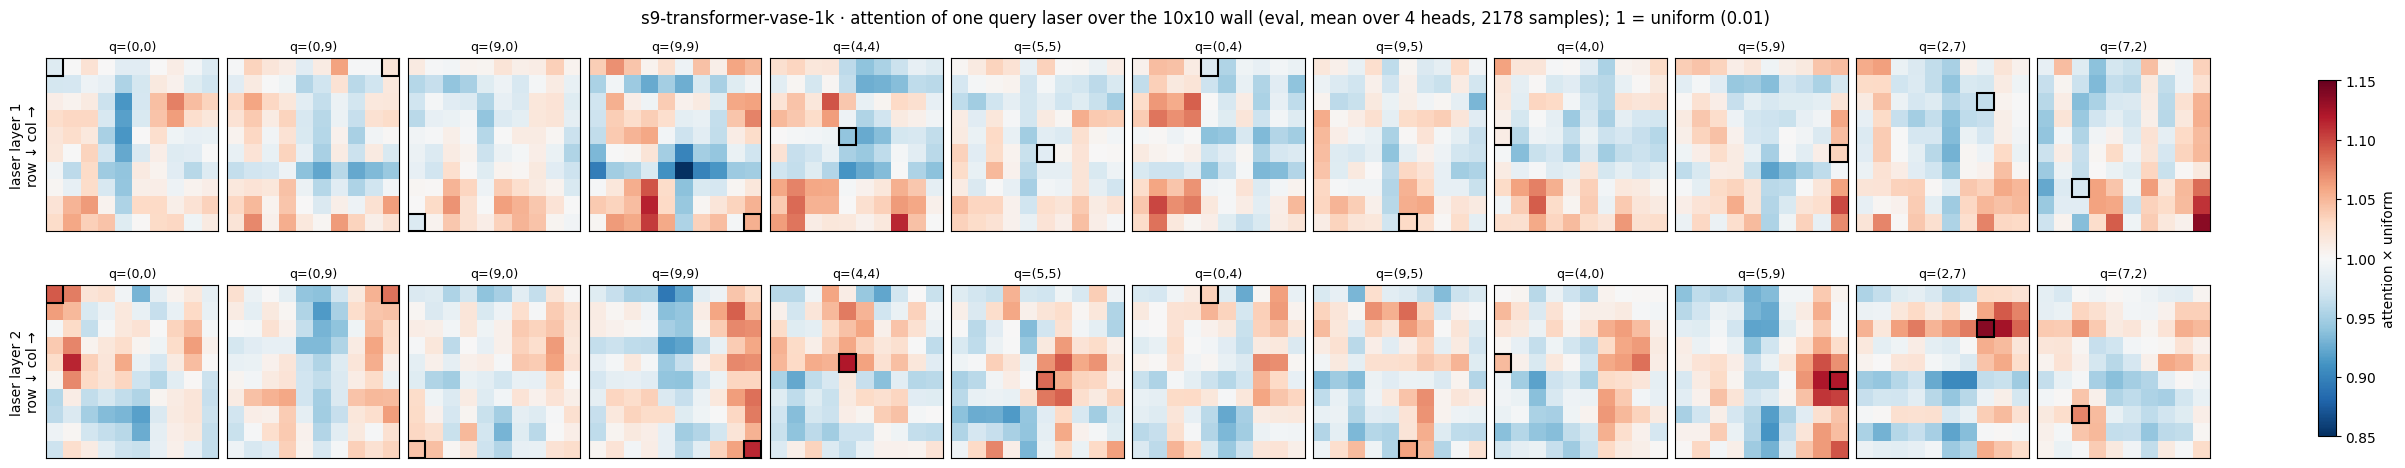

In [5]:
Q = [(0, 0), (0, 9), (9, 0), (9, 9), (4, 4), (5, 5), (0, 4), (9, 5), (4, 0), (5, 9), (2, 7), (7, 2)]   # corners, centre, edge middles, two inner
fig, axes = plt.subplots(2, len(Q), figsize=(2.0 * len(Q), 4.8), constrained_layout=True)
for r, n in enumerate(["laser0", "laser1"]):
    a = A_mean[n].mean(0) * L                                                      # (L,L) mean over heads, x uniform (1 = 1/100)
    for ax, (qr, qc) in zip(axes[r], Q):
        im = ax.imshow(a[qr * Cc + qc].reshape(R, Cc), cmap="RdBu_r", vmin=0.85, vmax=1.15)
        ax.add_patch(plt.Rectangle((qc - .5, qr - .5), 1, 1, fill=False, ec="black", lw=1.5))
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"q=({qr},{qc})", fontsize=9)
    axes[r, 0].set_ylabel(f"laser layer {r + 1}\nrow ↓ col →", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="attention × uniform")
fig.suptitle(f"{RUN} · attention of one query laser over the 10x10 wall (eval, mean over 4 heads, {len(EV)} samples); 1 = uniform (0.01)")
plt.show()

In [6]:
# how peaked / how local? per sample: the largest weight in a query row (uniform = 1/T), mean over rows + heads; and for the eval-mean
# laser maps the attention-weighted grid distance (cells) vs uniform
rc = np.stack(np.divmod(np.arange(L), Cc), 1); dist = np.linalg.norm(rc[:, None] - rc[None], axis=-1)   # (L,L) cells
for n in [*BLOCKS, "pool"]:
    T = L if n.startswith("laser") else NB
    line = f"{n:7s} max weight per row: median {np.median(peak[n]):.3f}, 99th pct {np.percentile(peak[n], 99):.3f} (uniform {1 / T:.3f})"
    if n.startswith("laser"): line += f" · mean distance {(A_mean[n].mean(0) * dist).sum(-1).mean():.2f} cells (uniform {dist.mean():.2f})"
    print(line)

freq0   max weight per row: median 0.082, 99th pct 0.095 (uniform 0.053)
freq1   max weight per row: median 0.082, 99th pct 0.092 (uniform 0.053)
laser0  max weight per row: median 0.020, 99th pct 0.025 (uniform 0.010) · mean distance 5.20 cells (uniform 5.19)
laser1  max weight per row: median 0.019, 99th pct 0.025 (uniform 0.010) · mean distance 5.17 cells (uniform 5.19)
pool    max weight per row: median 0.075, 99th pct 0.088 (uniform 0.053)


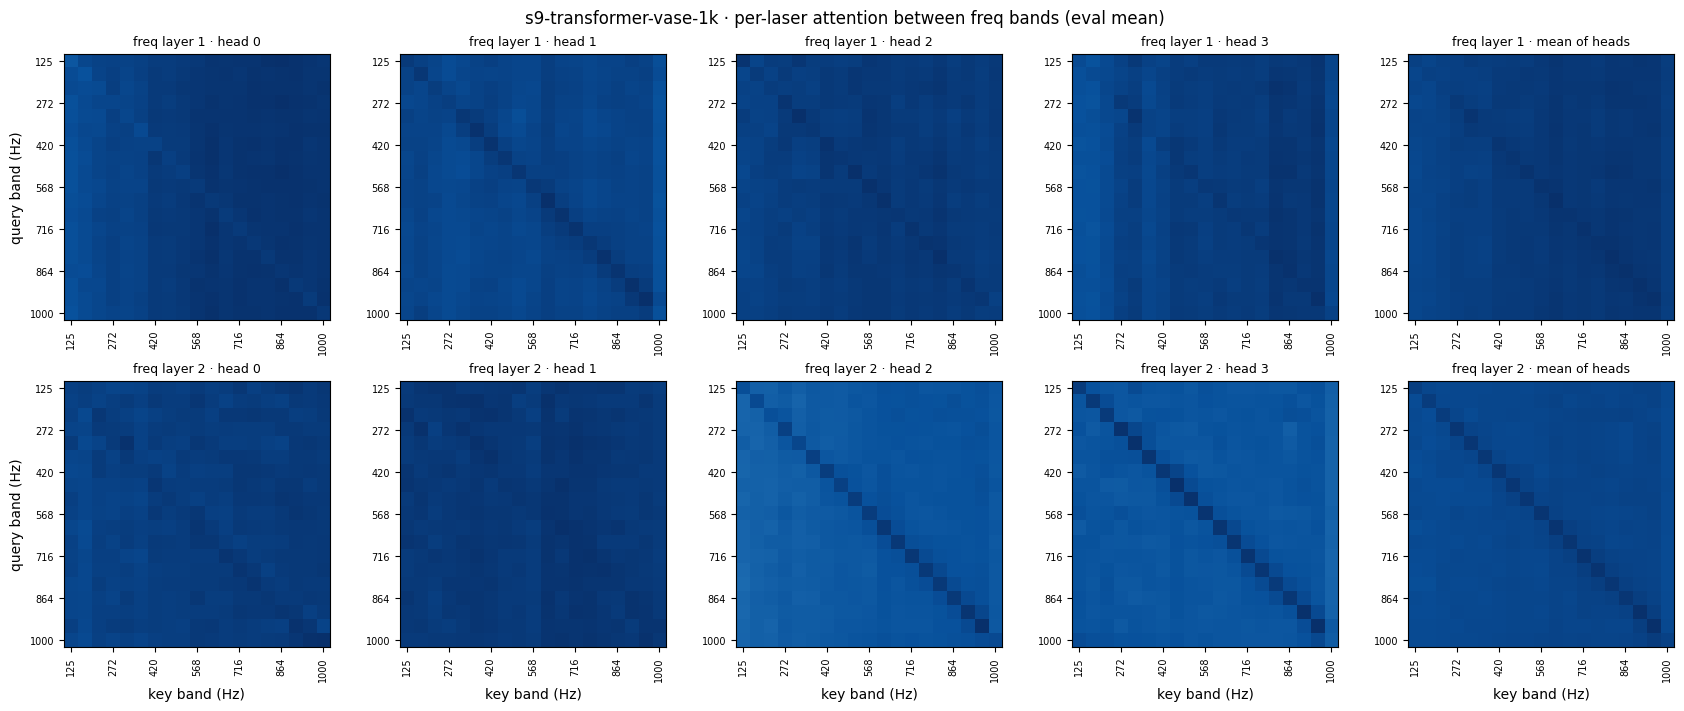

In [7]:
# the freq blocks: each laser's 19x19 band-to-band attention (mean over lasers, samples), per layer and head
fig, axes = plt.subplots(2, 5, figsize=(17, 7), constrained_layout=True)
for r, n in enumerate(["freq0", "freq1"]):
    for h in range(5):
        a = A_mean[n].mean(0) if h == 4 else A_mean[n][h]
        ax = axes[r, h]; ax.imshow(a, cmap="Blues", vmin=0)
        ax.set_title(f"freq layer {r + 1} · " + ("mean of heads" if h == 4 else f"head {h}"), fontsize=9)
        tk = np.arange(0, NB, 3); ax.set_xticks(tk, [f"{BAND_HZ[t]:.0f}" for t in tk], fontsize=7, rotation=90); ax.set_yticks(tk, [f"{BAND_HZ[t]:.0f}" for t in tk], fontsize=7)
    axes[r, 0].set_ylabel("query band (Hz)")
for ax in axes[1]: ax.set_xlabel("key band (Hz)")
fig.suptitle(f"{RUN} · per-laser attention between freq bands (eval mean)")
plt.show()

## 2b · the CLS analogs: what the embedding reads, per layer and rolled out
Top row (lasers, 10×10 wall): mean attention *received* in laser layers 1 and 2, the readout share (which slots write into the embedding), and the rollout (readout share pushed back through both laser layers with the residual identity). Bottom row (bands): mean attention received in freq layers 1 and 2, the `pool_q` attention (the one real learned-query/CLS-like softmax), and its rollout through both freq layers. Dashed = uniform.

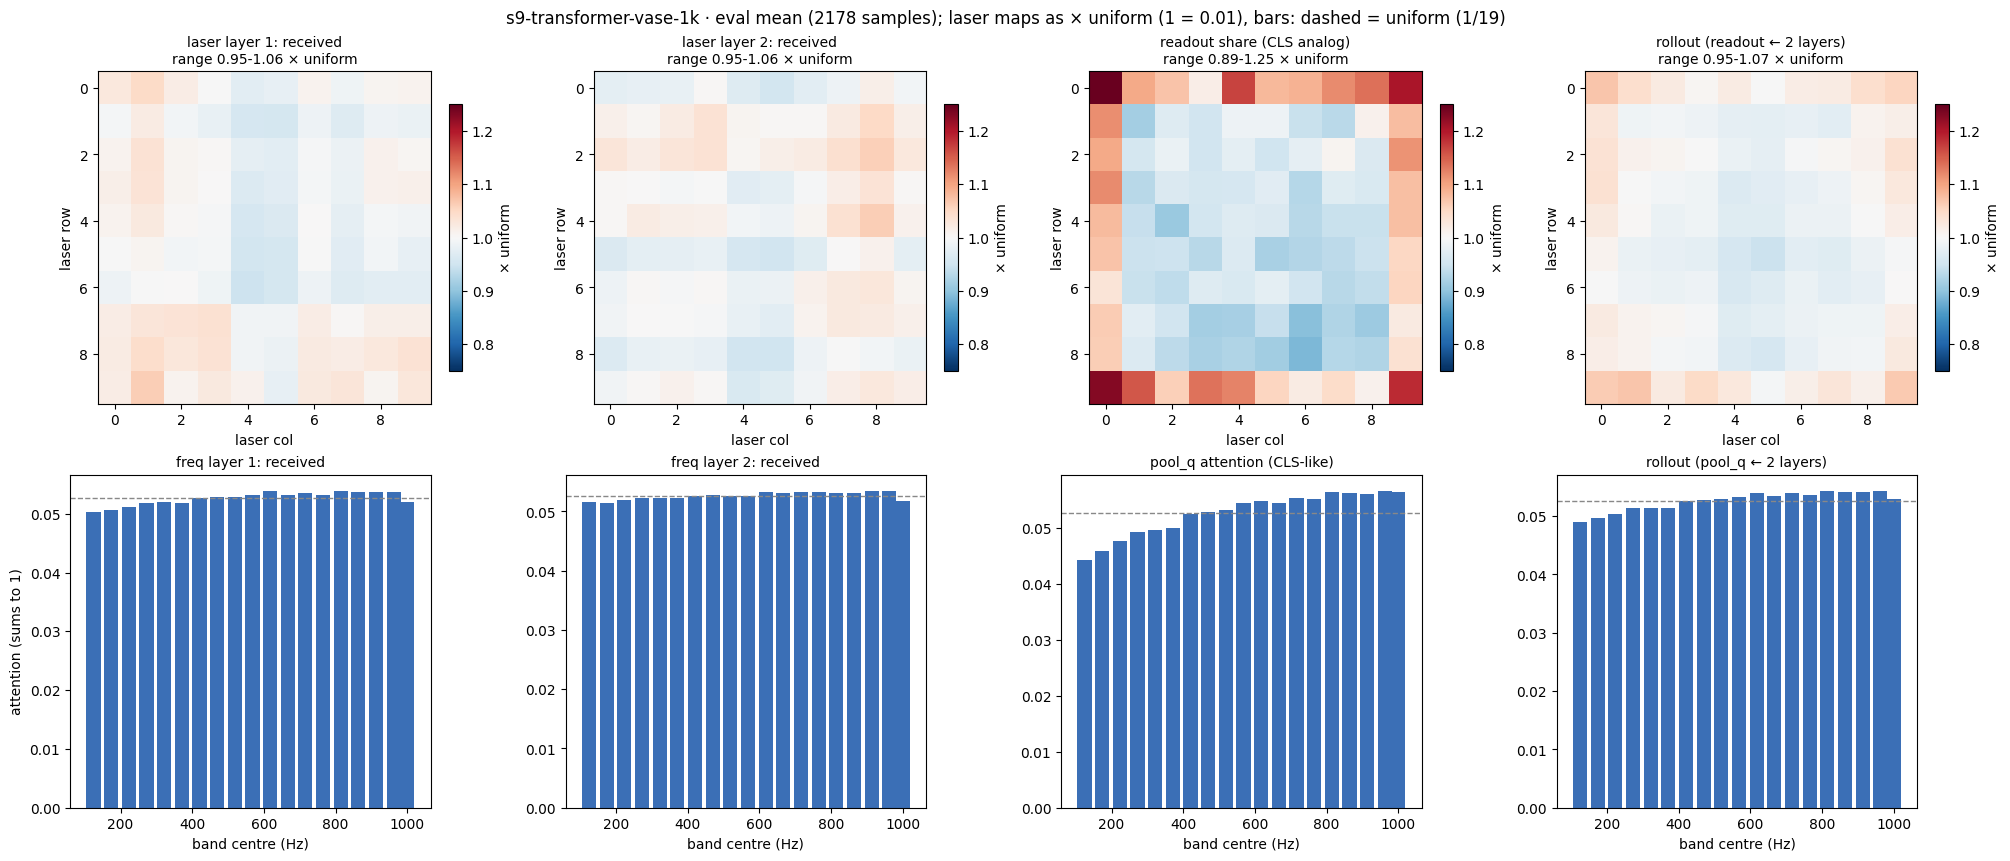

In [8]:
mean = lambda k: imp[k].mean(0)
laser = {"laser layer 1: received": mean("laser_recv0"), "laser layer 2: received": mean("laser_recv1"),
         "readout share (CLS analog)": mean("laser_read"), "rollout (readout ← 2 layers)": mean("laser_rollout")}
freq = {"freq layer 1: received": mean("freq_recv0"), "freq layer 2: received": mean("freq_recv1"),
        "pool_q attention (CLS-like)": mean("freq_cls"), "rollout (pool_q ← 2 layers)": mean("freq_rollout")}
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), constrained_layout=True)
for ax, (t, v) in zip(axes[0], laser.items()):
    im = ax.imshow(v.reshape(R, Cc) * L, cmap="RdBu_r", vmin=0.75, vmax=1.25); fig.colorbar(im, ax=ax, shrink=0.8, label="× uniform")
    ax.set_title(f"{t}\nrange {v.min() * L:.2f}-{v.max() * L:.2f} × uniform", fontsize=10); ax.set_xlabel("laser col"); ax.set_ylabel("laser row")
for ax, (t, v) in zip(axes[1], freq.items()):
    ax.bar(BAND_HZ, v, width=0.8 * (BAND_HZ[1] - BAND_HZ[0]), color="#3B6FB6")
    ax.axhline(1 / NB, color="#888888", ls="--", lw=1)
    ax.set_title(t, fontsize=10); ax.set_xlabel("band centre (Hz)"); ax.set_ylim(0, None)
axes[1, 0].set_ylabel("attention (sums to 1)")
fig.suptitle(f"{RUN} · eval mean ({len(EV)} samples); laser maps as × uniform (1 = 0.01), bars: dashed = uniform (1/19)")
plt.show()

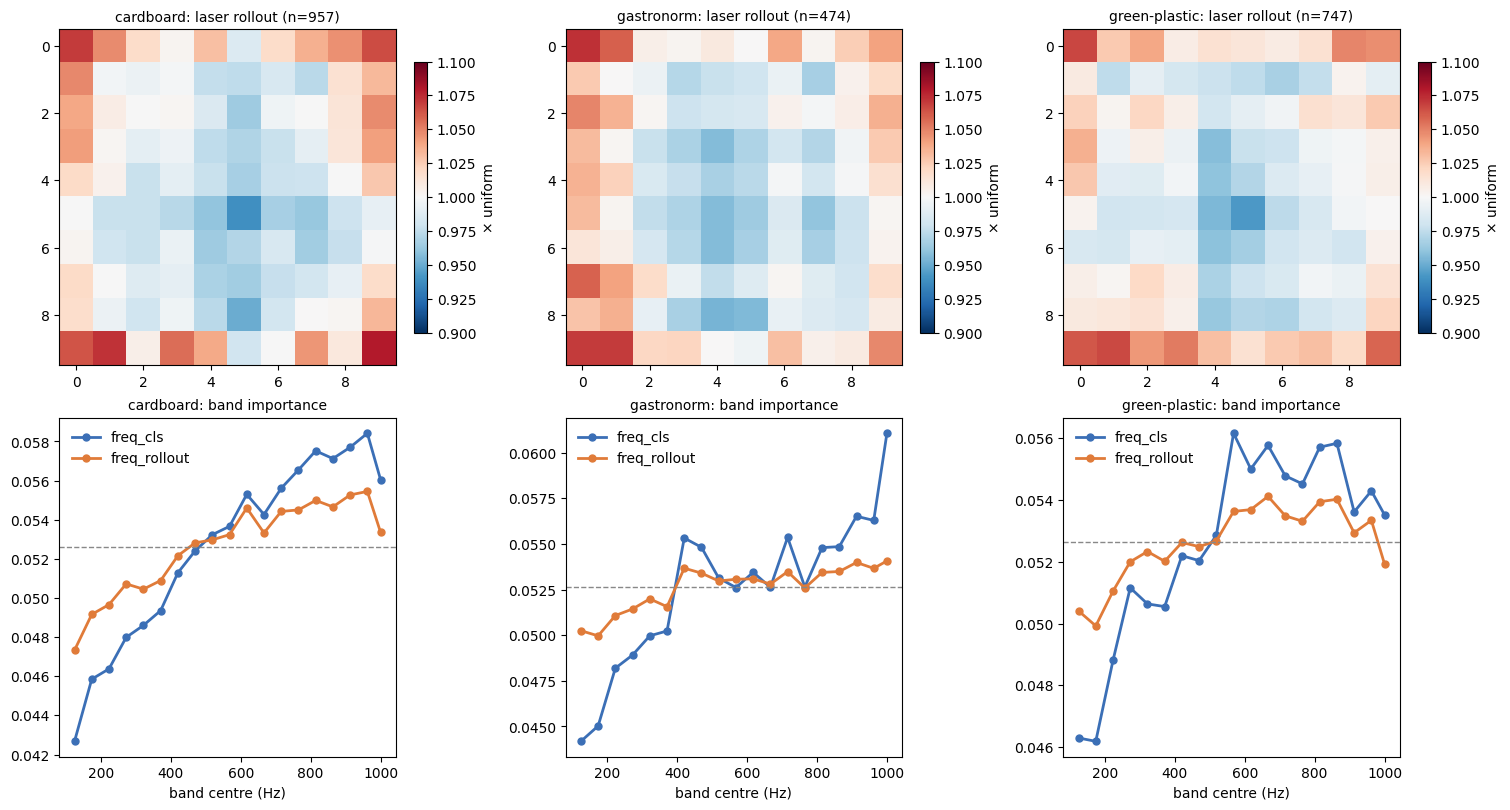

corr of laser rollout maps between boxes: [[1.0, 0.81, 0.84], [0.81, 1.0, 0.77], [0.84, 0.77, 1.0]]
laser rollout: per-sample std / std of the mean map = 2.0


In [9]:
# per box: do the boxes read the same lasers / bands?
boxes_ev = np.array([metas[i]["box"] for i in EV])
fig, axes = plt.subplots(2, len(boxes), figsize=(5 * len(boxes), 8), constrained_layout=True)
for c, b in enumerate(boxes):
    s = boxes_ev == b
    v = imp["laser_rollout"][s].mean(0)
    im = axes[0, c].imshow(v.reshape(R, Cc) * L, cmap="RdBu_r", vmin=0.9, vmax=1.1); fig.colorbar(im, ax=axes[0, c], shrink=0.8, label="× uniform")
    axes[0, c].set_title(f"{b}: laser rollout (n={s.sum()})", fontsize=10)
    for k, col in [("freq_cls", "#3B6FB6"), ("freq_rollout", "#E07B39")]:
        axes[1, c].plot(BAND_HZ, imp[k][s].mean(0), "o-", color=col, lw=2, ms=5, label=k)
    axes[1, c].axhline(1 / NB, color="#888888", ls="--", lw=1); axes[1, c].set_xlabel("band centre (Hz)"); axes[1, c].legend(frameon=False)
    axes[1, c].set_title(f"{b}: band importance", fontsize=10)
plt.show()
print("corr of laser rollout maps between boxes:", np.round(np.corrcoef([imp["laser_rollout"][boxes_ev == b].mean(0) for b in boxes]), 2).tolist())
print("laser rollout: per-sample std / std of the mean map =", round(float(imp["laser_rollout"].std(0).mean() / mean("laser_rollout").std()), 2))

In [10]:
# save the eval-mean importances: laser_* (L,) in token order (laser l = row l // 10, col l % 10), freq_* (19,) per band
out = ROOT / "notebooks/drafts_114/imp_attn.npz"
np.savez(out, laser_cls=mean("laser_read"), freq_cls=mean("freq_cls"), laser_rollout=mean("laser_rollout"), freq_rollout=mean("freq_rollout"),
         grid=np.array([R, Cc]), band_hz=BAND_HZ)
print(out, {k: v.shape for k, v in np.load(out).items()})

/home/ethantu/workspace/good-vibrations/notebooks/drafts_114/imp_attn.npz {'laser_cls': (100,), 'freq_cls': (19,), 'laser_rollout': (100,), 'freq_rollout': (19,), 'grid': (2,), 'band_hz': (19,)}


## findings
- **Attention is close to uniform everywhere.** Per sample, the largest weight in a query row is ~2× uniform at most (laser blocks: median 0.020 vs 0.010; freq blocks: 0.082 vs 0.053; `pool_q`: 0.075 vs 0.053). Averaged over samples it flattens further: every laser query map lies within about ±10% of 0.01, and the mean attended distance is the uniform one (5.2 cells). **The laser blocks do not route to specific lasers.** The only visible structure is in layer 2: the query and its immediate neighbours get about 1.1-1.15× uniform, a weak self/local bump. Each layer adds roughly the mean of all laser tokens (a global context vector) to every token, and the spatial information stays in the residual stream.
- **Freq blocks:** layer 1 is diffuse. Layer 2, heads 2 and 3, put mild extra weight on the band itself (the diagonal), so those heads are mostly per-band MLP-like. There is no cross-band pattern (no harmonics, no low→high routing).
- **Band pooling (`pool_q`, the only real CLS-like query):** a gentle tilt toward high frequencies, from 0.84× uniform at 125 Hz to 1.07× at ≥800 Hz. After rollout through the freq blocks it stays 0.93-1.03×. It works as a near-uniform gate, and the band selection happens in `pool_o`'s per-band weights, not in the softmax.
- **Lasers:** the readout share (each flatten slot's contribution to the embedding) is the most structured map, at 0.89-1.25× uniform. **Edge and corner lasers write more** (rows 0/9, cols 0/9) than the interior. The rollout keeps that border ring but flattens it to 0.95-1.07×. The pattern is shared by the boxes (map correlation 0.77-0.85), and per-sample variation is 2× the spatial contrast of the mean map. It is a weak, mostly sample-specific signal.
- **Does a last-token CLS work here? There isn't one.** The model reads all 100 laser slots with a flatten + Linear, which keeps laser identity. Given how uniform the laser attention is, a CLS token reading through these blocks would act close to mean pooling and lose the per-laser layout, which the flatten readout keeps. Attention maps say little about this model; use gradient or occlusion importances for attribution.